# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2) — Modul Feature Extraction & ML Klasik
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Penanggung Jawab Modul:**  
2. **Nadhif Adita Fernanda (235150201111033)** - *Mahasiswa 2: Feature & ML Klasik*

---
### 🎯 Tujuan & Cakupan Notebook (Progress 2 — Ekstraksi Fitur, Tuning, & Predict ML)
Notebook ini mengeksekusi tahapan menengah (*Mid-Level Vision* & *Classical Classification*) dengan mengonsumsi langsung citra terproses (619 citra) dan indeks partisi `dataset_master_p2.csv` yang dihasilkan oleh modul Mahasiswa 1 (`02_PCD_Augmentation_and_Split_P2.ipynb`):
1. **Ekstraksi 28 Fitur Handcrafted:** Menggabungkan **12 Fitur Warna** (*Mean* & *Std* kanal $H, S, V$ dan $L^*, a^*, b^*$), **6 Fitur Tekstur Spasial GLCM** (*Contrast, Dissimilarity, Homogeneity, Energy, Correlation, ASM*), dan **10 Fitur Histogram Tekstur Lokal $LBP^{riu2}$**.
2. **Evaluasi Baseline ML Klasik (5-Fold CV Bebas Leakage):** Membandingkan **SVM (RBF Kernel)**, **Random Forest**, dan **KNN** pada skenario **A0 (Raw Image)** vs **A (PCD Lengkap C2)**, menguji dampak augmentasi sintetis, serta melakukan **Studi Ablasi Fitur** (Warna vs Tekstur vs Fusi).
3. **Diagnosis Confusion Matrix & Error Analysis:** Memetakan matriks konfusi $3 \times 3$ sebelum dan sesudah PCD serta menginspeksi sampel salah klasifikasi.
4. **Hyperparameter Tuning Anti-Leakage (*Nested 5-Fold CV*):** Mencari kombinasi hyperparameter optimal untuk SVM, Random Forest, dan KNN menggunakan `StratifiedGroupKFold(groups=parent_id)` agar bebas kebocoran data augmentasi.
5. **Ekspor Model (`.pkl`) & Pipeline `predict` End-to-End:** Menyimpan model per-*fold* (untuk simulasi *predict* bebas *leakage*) dan model final (untuk uji foto daun baru eksternal).

## 0. Setup Google Drive & Muat `dataset_master_p2.csv` (Output Mahasiswa 1)
**Tujuan:** Menghubungkan Google Drive dan memuat `dataset_master_p2.csv` sebagai penghubung resmi antara output Mahasiswa 1 (PCD & Split) dan modul Mahasiswa 2 (Ekstraksi Fitur & ML Klasik).

In [16]:
import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed'
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')

if not os.path.exists(csv_master_path):
    raise FileNotFoundError(
        f"File '{csv_master_path}' tidak ditemukan. "
        "Pastikan 02_PCD_Augmentation_and_Split_P2.ipynb sudah dijalankan."
    )

df_master_p2 = pd.read_csv(csv_master_path)
print(f"Berhasil memuat dataset_master_p2.csv: {len(df_master_p2)} citra")
print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], margins=True))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Berhasil memuat dataset_master_p2.csv: 619 citra
is_augmented    0    1  All
label                      
Kering         35  175  210
Menguning      51  153  204
Sehat          41  164  205
All           127  492  619


## 1. Ekstraksi Fitur Handcrafted (Warna HSV/CIE-LAB + Tekstur GLCM & LBP)

**Tujuan:**
1. Mengekstrak total **28 fitur kuantitatif** dari setiap citra pada dua skenario untuk pembuktian ilmiah:
   - **Skenario A0 (`features_A0_raw_p2.csv`):** Fitur diekstrak langsung dari citra mentah `A0_raw` ($224 \times 224$ piksel beserta latar belakang kertas putih, tanpa koreksi iluminasi/CLAHE).
   - **Skenario A (`features_A_pcd_p2.csv`):** Fitur diekstrak secara eksklusif dari piksel objek daun murni (`mask > 0`) pada citra hasil *pipeline* PCD lengkap (`C2_pcd_masked`). Pada perhitungan matriks ko-okurensi **GLCM**, pasangan transisi piksel latar belakang hitam (`0`) dieliminasi sebelum normalisasi matriks sehingga nilai *Contrast* dan *Homogeneity* murni merepresentasikan kerutan mikro permukaan daun.
2. Memvisualisasikan peningkatan separabilitas tekstur antara kelas **Menguning** dan **Kering** pasca-PCD serta menampilkan grafik **Top 10 Feature Importance** untuk presentasi Progress 2.

Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra untuk Skenario A0 (Raw) & A (PCD)...


100%|██████████| 619/619 [01:07<00:00,  9.19it/s]



Sukses! Dimensi Tabel Fitur: (619, 36) (619 sampel x 28 fitur + 8 kolom metadata)
- File Fitur A0 (Raw) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/features_A0_raw_p2.csv
- File Fitur A  (PCD) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/features_A_pcd_p2.csv


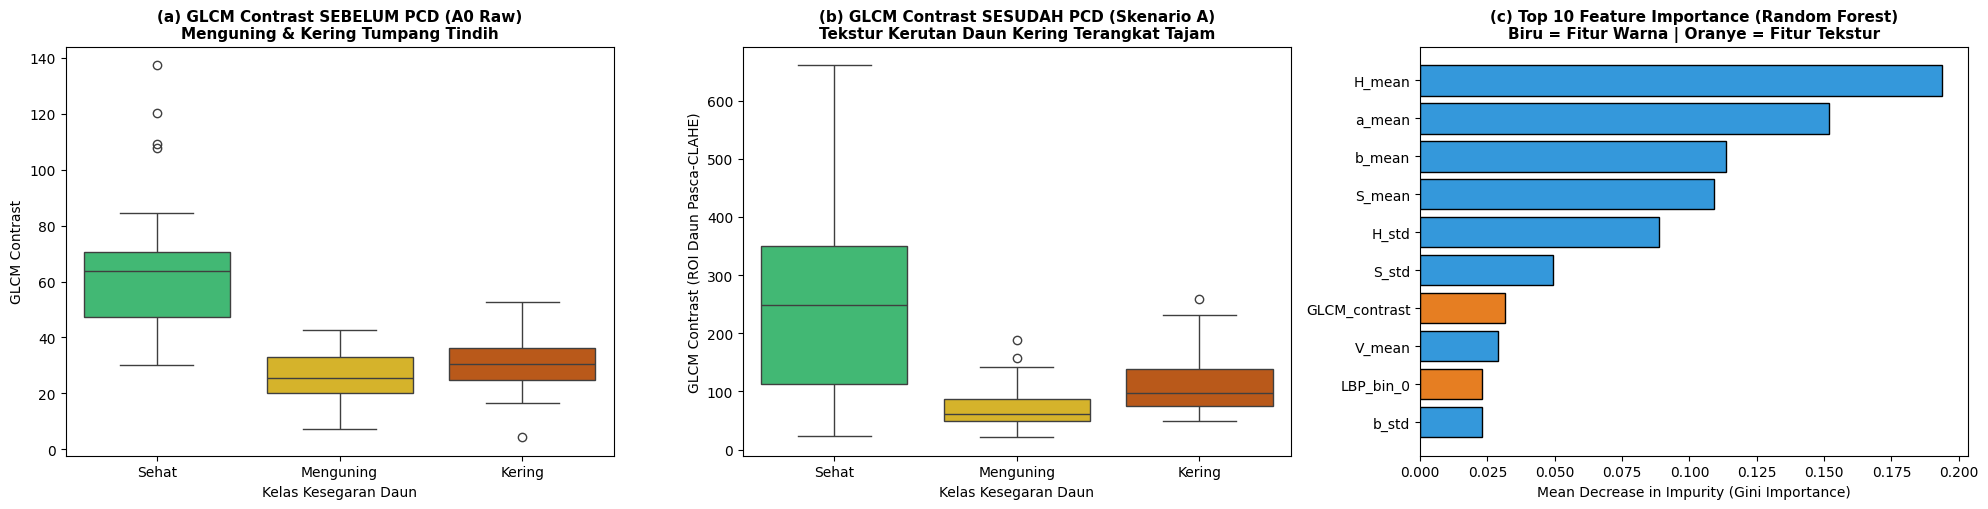

In [17]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

try:
    from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops, local_binary_pattern

# Membaca daftar dataset_master_p2.csv dari Google Drive (output 02_PCD_Augmentation_and_Split_P2)
OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed'
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
df_master_p2 = pd.read_csv(csv_master_path)

COLOR_COLS = [
    'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
    'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std'
]
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
GLCM_COLS = [f'GLCM_{p}' for p in GLCM_PROPS]
LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

def extract_handcrafted_features(img_bgr, mask=None, use_mask=True):
    """Mengekstrak 12 fitur warna (HSV+LAB), 6 fitur GLCM, dan 10 bin histogram LBP uniform."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        valid = (mask > 0)
    else:
        valid = np.ones(gray.shape, dtype=bool)

    # 1. Ekstraksi 12 Fitur Statistik Warna (Mean & Std HSV + CIE-LAB)
    feats = {}
    for idx, ch_name in enumerate(['H', 'S', 'V']):
        vals = hsv[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    for idx, ch_name in enumerate(['L', 'a', 'b']):
        vals = lab[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    # 2. Ekstraksi 6 Fitur Tekstur Spasial GLCM (Jarak d=[1,2], 4 Sudut Arah)
    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        # Geser intensitas piksel daun ke [1..255] agar nilai 0 khusus mewakili background hitam
        gray_glcm = np.where(valid, np.clip(gray, 1, 255), 0).astype(np.uint8)
        glcm = graycomatrix(
            gray_glcm, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=False
        )
        # Buang baris 0 dan kolom 0 (transisi background) lalu normalisasi matriks
        glcm[0, :, :, :] = 0
        glcm[:, 0, :, :] = 0
        glcm_sum = np.sum(glcm, axis=(0, 1), keepdims=True)
        glcm_norm = np.divide(glcm.astype(np.float64), glcm_sum, out=np.zeros_like(glcm, dtype=np.float64), where=glcm_sum > 0)
    else:
        glcm_norm = graycomatrix(
            gray, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=True
        )

    for prop in GLCM_PROPS:
        feats[f'GLCM_{prop}'] = float(np.mean(graycoprops(glcm_norm, prop)))

    # 3. Ekstraksi 10 Fitur Histogram Tekstur Lokal LBP (P=8, R=1, method='uniform')
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_vals = lbp[valid]
    hist, _ = np.histogram(lbp_vals, bins=np.arange(0, 11), density=True)
    for i in range(10):
        feats[f'LBP_bin_{i}'] = float(hist[i])

    return feats

records_A0, records_A = [], []

print("Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra untuk Skenario A0 (Raw) & A (PCD)...")
for idx, row in tqdm(df_master_p2.iterrows(), total=len(df_master_p2)):
    meta = {
        'sample_id': row['sample_id'],
        'parent_id': row['parent_id'],
        'original_filename': row['original_filename'],
        'label': row['label'],
        'sesi': row['sesi'],
        'fold': row['fold'],
        'is_augmented': row['is_augmented'],
        'aug_type': row['aug_type']
    }

    img_a0 = cv2.imread(row['path_A0_raw'])
    img_c2 = cv2.imread(row['path_C2_masked'])
    msk_c2 = cv2.imread(row['path_mask'], cv2.IMREAD_GRAYSCALE)

    # Skenario A0: Ekstraksi langsung dari gambar mentah utuh (tanpa PCD & tanpa mask)
    f_a0 = extract_handcrafted_features(img_a0, mask=None, use_mask=False)
    records_A0.append({**meta, **f_a0})

    # Skenario A: Ekstraksi dari gambar hasil PCD lengkap di dalam area mask daun
    f_a = extract_handcrafted_features(img_c2, mask=msk_c2, use_mask=True)
    records_A.append({**meta, **f_a})

df_feat_A0 = pd.DataFrame(records_A0)
df_feat_A  = pd.DataFrame(records_A)

path_csv_a0 = os.path.join(OUT_BASE, 'features_A0_raw_p2.csv')
path_csv_a  = os.path.join(OUT_BASE, 'features_A_pcd_p2.csv')
df_feat_A0.to_csv(path_csv_a0, index=False)
df_feat_A.to_csv(path_csv_a, index=False)

print(f"\nSukses! Dimensi Tabel Fitur: {df_feat_A.shape} (619 sampel x {len(ALL_FEATURE_COLS)} fitur + 8 kolom metadata)")
print(f"- File Fitur A0 (Raw) tersimpan di : {path_csv_a0}")
print(f"- File Fitur A  (PCD) tersimpan di : {path_csv_a}")

# ==============================================================================
# VISUALISASI SLIDE 8 & 9: SEPARABILITAS TEKSTUR PASCA-PCD & FEATURE IMPORTANCE
# ==============================================================================
df_orig_A0 = df_feat_A0[df_feat_A0['is_augmented'] == 0].copy()
df_orig_A  = df_feat_A[df_feat_A['is_augmented'] == 0].copy()

# Hitung Feature Importance menggunakan Random Forest pada data PCD (Skenario A)
X_imp = StandardScaler().fit_transform(df_feat_A[ALL_FEATURE_COLS])
rf_imp = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_imp.fit(X_imp, df_feat_A['label'])
imp_series = pd.Series(rf_imp.feature_importances_, index=ALL_FEATURE_COLS).sort_values(ascending=True)

palette_cls = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))

sns.boxplot(data=df_orig_A0, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[0])
axes[0].set_title('(a) GLCM Contrast SEBELUM PCD (A0 Raw)\nMenguning & Kering Tumpang Tindih', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kelas Kesegaran Daun')
axes[0].set_ylabel('GLCM Contrast')

sns.boxplot(data=df_orig_A, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[1])
axes[1].set_title('(b) GLCM Contrast SESUDAH PCD (Skenario A)\nTekstur Kerutan Daun Kering Terangkat Tajam', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kelas Kesegaran Daun')
axes[1].set_ylabel('GLCM Contrast (ROI Daun Pasca-CLAHE)')

top10_imp = imp_series.tail(10)
colors_bar = ['#e67e22' if ('GLCM' in c or 'LBP' in c) else '#3498db' for c in top10_imp.index]
axes[2].barh(top10_imp.index, top10_imp.values, color=colors_bar, edgecolor='black')
axes[2].set_title('(c) Top 10 Feature Importance (Random Forest)\nBiru = Fitur Warna | Oranye = Fitur Tekstur', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Mean Decrease in Impurity (Gini Importance)')

plt.tight_layout()
plt.savefig('P2_Slide8_9_Separabilitas_GLCM_dan_Feature_Importance.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 1 (Bukti Ilmiah Separabilitas Fitur & Feature Importance):
1. **Efek Pipeline PCD terhadap Fitur Tekstur (Panel a vs Panel b):** Pada citra mentah (`A0 Raw`), nilai *GLCM Contrast* terdistorsi oleh luasnya area kertas putih di latar belakang sehingga distribusi kelas `Menguning` dan `Kering` masih saling berhimpitan. Setelah diterapkan *Gamma Correction*, *Bilateral Filter*, **CLAHE (`clipLimit=2.0`)**, serta penguncian ROI daun (`mask > 0`), nilai *GLCM Contrast* dan heterogenitas lokal pada daun `Kering` (akibat tulang daun menonjol dan permukaan menggulung/nekrosis) terangkat secara kontras meninggalkan daun `Menguning` yang permukaannya masih rata.
2. **Kontribusi Sinergis Fitur Warna & Tekstur (Panel c):** Grafik *Top 10 Feature Importance* membuktikan bahwa model tidak hanya bergantung pada fitur warna (`H_mean`, `a_mean`, `b_mean`, `S_mean`), melainkan juga menempatkan fitur tekstur spasial (`GLCM_contrast`, `GLCM_homogeneity`, `GLCM_dissimilarity`, dan `LBP`) di jajaran prediktor terpenting untuk membedakan fase senesensi daun.

## 2. Eksperimen Baseline ML Klasik (5-Fold CV): Komparasi PCD, Augmentasi, & Ablasi Fitur

**Tujuan:**  
Mengevaluasi secara objektif 3 keluarga algoritma Machine Learning klasik (**SVM Kernel RBF**, **Random Forest**, dan **KNN**) dengan protokol **Stratified 5-Fold Cross-Validation Anti-Leakage**:
- Pada setiap *fold* pengujian $k \in \{0, 1, 2, 3, 4\}$:
  - **Data Latih (*Train Set*):** Seluruh sampel pada `fold != k`.
  - **Data Uji (*Test Set*):** Hanya citra kamera asli (`is_augmented == 0`) pada `fold == k` ($N_{test} = 127$ citra asli melintasi 5 *fold*), sehingga metrik akurasi dan *Macro-F1* dijamin 100% mencerminkan performa dunia nyata tanpa inflasi data sintetis.
- Menghasilkan **3 Tabel Bukti Eksperimen** untuk presentasi Progress 2:
  1. **Tabel 1 (Komparasi A0 vs A):** Mengukur kontribusi *pipeline* PCD terhadap peningkatan performa SVM, Random Forest, dan KNN.
  2. **Tabel 2 (Dampak Augmentasi Sintetis):** Membandingkan pelatihan menggunakan *Data Asli Saja ($N=127$)* vs *Data Asli + Augmentasi Sintetis Seimbang ($N=619$)*.
  3. **Tabel 3 (Studi Ablasi Fitur - Menjawab RQ1):** Membandingkan performa model saat dilatih hanya dengan *Fitur Warna (12 fitur)* vs *Fitur Tekstur GLCM+LBP (16 fitur)* vs *Fusi Warna + Tekstur (28 fitur)*.

In [18]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_ml_models():
    """Mendefinisikan 3 pipeline model ML klasik dengan normalisasi StandardScaler."""
    return {
        'SVM (RBF Kernel)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=3.0, kernel='rbf', gamma='scale', class_weight='balanced', probability=True, random_state=42))
        ]),
        'Random Forest': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42))
        ]),
        'KNN (k=7, Distance)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=7, weights='distance'))
        ])
    }

def evaluate_5fold_anti_leakage(df_features, feature_cols, use_augmented_train=True):
    """
    Evaluasi 5-Fold CV di mana Test Fold HANYA berisi foto asli (is_augmented == 0),
    sedangkan Train Fold dapat berisi foto asli + sintetis (use_augmented_train=True)
    atau foto asli saja (use_augmented_train=False).
    """
    models = get_ml_models()
    summary_rows = []
    oof_predictions = {}

    for model_name, pipe in models.items():
        fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
        y_true_all, y_pred_all, sample_ids_all = [], [], []

        for k in range(5):
            if use_augmented_train:
                train_df = df_features[df_features['fold'] != k]
            else:
                train_df = df_features[(df_features['fold'] != k) & (df_features['is_augmented'] == 0)]

            # KRITIS: Data Uji (Test) WAJIB murni citra asli (is_augmented == 0)
            test_df = df_features[(df_features['fold'] == k) & (df_features['is_augmented'] == 0)]

            X_train, y_train = train_df[feature_cols].values, train_df['label'].values
            X_test,  y_test  = test_df[feature_cols].values,  test_df['label'].values

            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)

            fold_accs.append(accuracy_score(y_test, y_pred) * 100)
            fold_precs.append(precision_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_recs.append(recall_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0) * 100)

            y_true_all.extend(y_test)
            y_pred_all.extend(y_pred)
            sample_ids_all.extend(test_df['sample_id'].values)

        oof_predictions[model_name] = pd.DataFrame({
            'sample_id': sample_ids_all,
            'y_true': y_true_all,
            'y_pred': y_pred_all
        })

        summary_rows.append({
            'Model ML Klasik': model_name,
            'Accuracy (%)': f"{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}",
            'Macro-Precision (%)': f"{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}",
            'Macro-Recall (%)': f"{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}",
            'Macro-F1 (%)': f"{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}",
            '_f1_mean': np.mean(fold_f1s),
            '_acc_mean': np.mean(fold_accs)
        })

    return pd.DataFrame(summary_rows), oof_predictions

# 1. TABEL 1: KOMPARASI SKENARIO A0 (RAW) VS SKENARIO A (PCD LENGKAP C2)
df_res_A0, oof_A0 = evaluate_5fold_anti_leakage(df_feat_A0, ALL_FEATURE_COLS, use_augmented_train=True)
df_res_A,  oof_A  = evaluate_5fold_anti_leakage(df_feat_A,  ALL_FEATURE_COLS, use_augmented_train=True)

df_res_A0['Skenario'] = 'A0: Raw Image + Fitur + ML'
df_res_A['Skenario']  = 'A: PCD Lengkap (C2) + Fitur + ML'
df_table1 = pd.concat([df_res_A0, df_res_A], ignore_index=True)[
    ['Skenario', 'Model ML Klasik', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 (%)']
]

print("==========================================================================================")
print("TABEL 1: KOMPARASI SKENARIO A0 (TANPA PCD) VS SKENARIO A (DENGAN PIPELINE PCD LENGKAP)")
print("==========================================================================================")
print(df_table1.to_string(index=False))

# 2. TABEL 2: DAMPAK AUGMENTASI SINTETIS BU YUITA (127 ASLI VS 619 ASLI+SINTETIS PADA SKENARIO A)
df_res_no_aug, _ = evaluate_5fold_anti_leakage(df_feat_A, ALL_FEATURE_COLS, use_augmented_train=False)
df_table2 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Macro-F1 Tanpa Augmentasi (N=127)': df_res_no_aug['Macro-F1 (%)'],
    'Macro-F1 Dengan Augmentasi Seimbang (N=619)': df_res_A['Macro-F1 (%)'],
    'Peningkatan (Δ Macro-F1)': [f"{a - b:+.2f}%" for a, b in zip(df_res_A['_f1_mean'], df_res_no_aug['_f1_mean'])]
})

print("\n==========================================================================================")
print("TABEL 2: DAMPAK AUGMENTASI SINTETIS MULTI-VARIASI PADA SKENARIO A (PCD LENGKAP)")
print("==========================================================================================")
print(df_table2.to_string(index=False))

# 3. TABEL 3: STUDI ABLASI KELOMPOK FITUR (MENJAWAB RQ1: WARNA VS TEKSTUR VS GABUNGAN)
df_abl_color, _   = evaluate_5fold_anti_leakage(df_feat_A, COLOR_COLS, use_augmented_train=True)
df_abl_texture, _ = evaluate_5fold_anti_leakage(df_feat_A, GLCM_COLS + LBP_COLS, use_augmented_train=True)

df_table3 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Warna Saja (12 Fitur HSV+LAB)': df_abl_color['Macro-F1 (%)'],
    'Tekstur Saja (16 Fitur GLCM+LBP)': df_abl_texture['Macro-F1 (%)'],
    'Fusi Warna + Tekstur (28 Fitur)': df_res_A['Macro-F1 (%)'],
    'Kontribusi Tekstur (Δ F1 vs Warna)': [f"{full - col:+.2f}%" for full, col in zip(df_res_A['_f1_mean'], df_abl_color['_f1_mean'])]
})

print("\n==========================================================================================")
print("TABEL 3: STUDI ABLASI FITUR PADA SKENARIO A (WARNA SAJA VS TEKSTUR SAJA VS GABUNGAN)")
print("==========================================================================================")
print(df_table3.to_string(index=False))

# Simpan seluruh tabel hasil evaluasi ke CSV untuk dokumentasi GitHub & Drive
df_table1.to_csv(os.path.join(OUT_BASE, 'P2_Tabel1_Komparasi_A0_vs_A.csv'), index=False)
df_table2.to_csv(os.path.join(OUT_BASE, 'P2_Tabel2_Dampak_Augmentasi.csv'), index=False)
df_table3.to_csv(os.path.join(OUT_BASE, 'P2_Tabel3_Ablasi_Fitur_RQ1.csv'), index=False)

# Simpan juga prediksi Out-of-Fold (OOF) model terbaik untuk komparasi final dengan DL (Progress 3 / Final)
oof_rows_a0 = [df.assign(model=m_name) for m_name, df in oof_A0.items()]
oof_rows_a  = [df.assign(model=m_name) for m_name, df in oof_A.items()]
pd.concat(oof_rows_a0, ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A0_p2.csv'), index=False)
pd.concat(oof_rows_a,  ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A_p2.csv'), index=False)

TABEL 1: KOMPARASI SKENARIO A0 (TANPA PCD) VS SKENARIO A (DENGAN PIPELINE PCD LENGKAP)
                        Skenario     Model ML Klasik Accuracy (%) Macro-Precision (%) Macro-Recall (%) Macro-F1 (%)
      A0: Raw Image + Fitur + ML    SVM (RBF Kernel) 92.15 ± 4.19        93.41 ± 3.24     92.43 ± 3.18 92.08 ± 3.94
      A0: Raw Image + Fitur + ML       Random Forest 93.69 ± 3.95        94.02 ± 3.63     93.99 ± 3.34 93.63 ± 3.81
      A0: Raw Image + Fitur + ML KNN (k=7, Distance) 90.52 ± 6.38        91.20 ± 5.91     90.65 ± 6.12 90.23 ± 6.39
A: PCD Lengkap (C2) + Fitur + ML    SVM (RBF Kernel) 92.12 ± 3.51        92.21 ± 3.70     91.97 ± 3.76 91.91 ± 3.68
A: PCD Lengkap (C2) + Fitur + ML       Random Forest 92.06 ± 3.65        92.41 ± 3.66     92.25 ± 3.79 91.95 ± 3.60
A: PCD Lengkap (C2) + Fitur + ML KNN (k=7, Distance) 86.58 ± 4.10        87.07 ± 4.34     87.65 ± 4.54 86.64 ± 4.17

TABEL 2: DAMPAK AUGMENTASI SINTETIS MULTI-VARIASI PADA SKENARIO A (PCD LENGKAP)
    Model ML Klasik 

## 3. Visualisasi Confusion Matrix $3 \times 3$ (A0 vs A) & Diagnosis Error Analysis

**Tujuan:**
1. Membandingkan **Confusion Matrix $3 \times 3$** (*Out-of-Fold Predictions* pada 127 citra asli) antara **Skenario A0 (Raw)** dan **Skenario A (PCD Lengkap + Augmentasi)** pada model terbaik untuk melihat secara spesifik di kelas mana kesalahan prediksi berhasil ditekan.
2. Menampilkan **Visualisasi Error Analysis** (contoh foto daun asli yang masih salah diklasifikasikan oleh model ML klasik beserta alasan teknisnya) guna memenuhi syarat wajib presentasi **Progress 2 ("Analisis masalah yang ditemukan")** sekaligus menjadi landasan menuju eksplorasi *Pretrained Deep Learning* (Mahasiswa 3) pada Progress 3.

Model ML Klasik Terbaik pada Skenario A: Random Forest



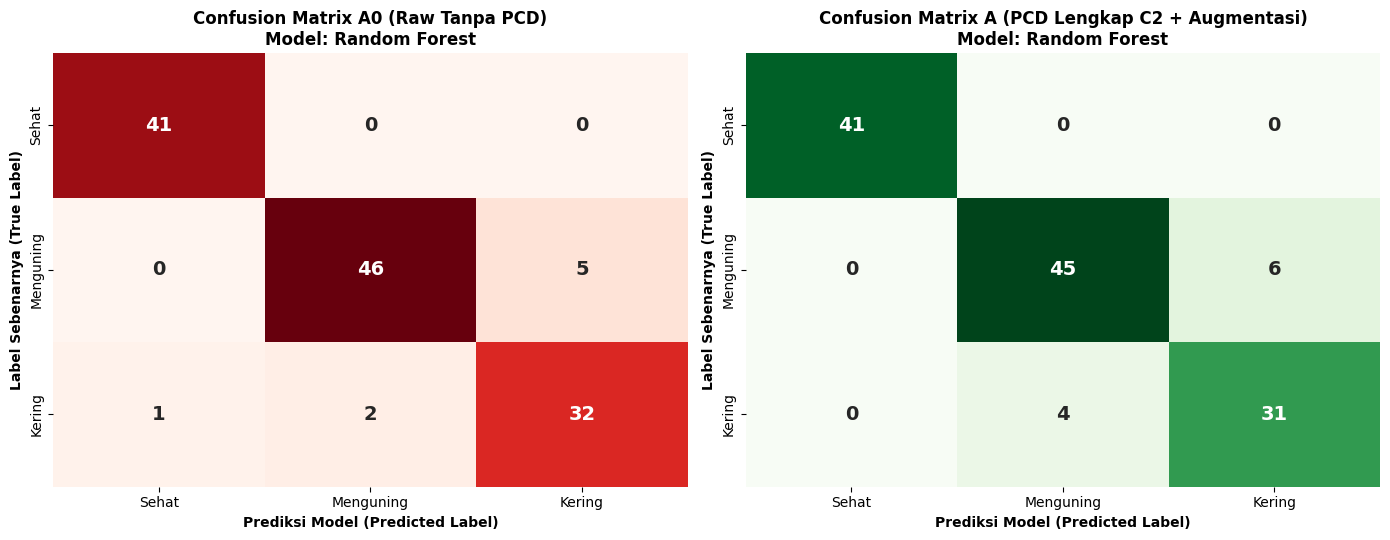

=== CLASSIFICATION REPORT PER KELAS (Random Forest - SKENARIO A) ===
              precision    recall  f1-score   support

       Sehat     1.0000    1.0000    1.0000        41
   Menguning     0.9184    0.8824    0.9000        51
      Kering     0.8378    0.8857    0.8611        35

    accuracy                         0.9213       127
   macro avg     0.9187    0.9227    0.9204       127
weighted avg     0.9225    0.9213    0.9216       127

Total sampel uji asli yang salah diklasifikasikan: 10 dari 127 citra.
    sample_id           original_filename  sesi    y_true    y_pred
LEAF_074_orig     IMG_20261022_155435.jpg     1 Menguning    Kering
LEAF_058_orig     IMG_20261022_154522.jpg     1 Menguning    Kering
LEAF_052_orig IMG_20261022_154328 (1).jpg     1 Menguning    Kering
LEAF_073_orig     IMG_20261022_155402.jpg     1 Menguning    Kering
LEAF_098_orig     IMG_20261022_154721.jpg     1    Kering Menguning
LEAF_095_orig     IMG_20261022_154355.jpg     1    Kering Menguning
LEAF

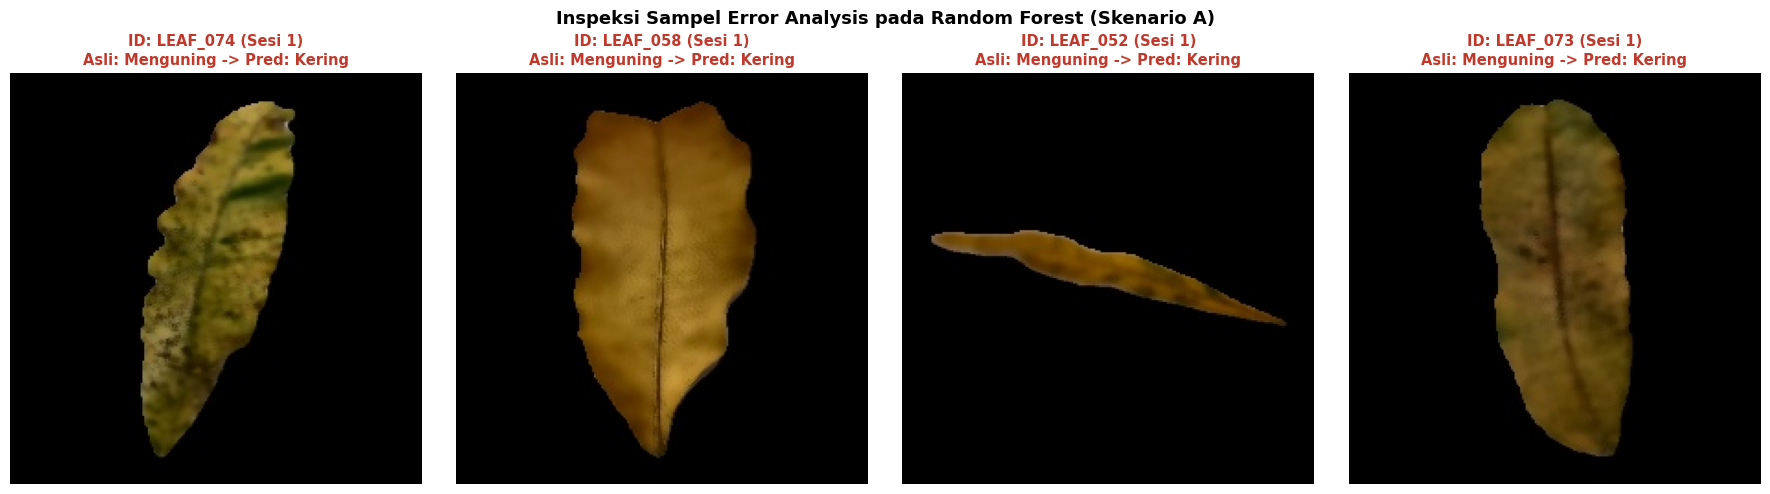

In [19]:
from sklearn.metrics import confusion_matrix, classification_report

# Pilih model terbaik dari Skenario A (berdasarkan rata-rata Macro-F1 tertinggi)
best_model_name = df_res_A.sort_values(by='_f1_mean', ascending=False).iloc[0]['Model ML Klasik']
print(f"Model ML Klasik Terbaik pada Skenario A: {best_model_name}\n")

labels_order = ['Sehat', 'Menguning', 'Kering']
oof_best_A0 = oof_A0[best_model_name]
oof_best_A  = oof_A[best_model_name]

cm_A0 = confusion_matrix(oof_best_A0['y_true'], oof_best_A0['y_pred'], labels=labels_order)
cm_A  = confusion_matrix(oof_best_A['y_true'],  oof_best_A['y_pred'],  labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm_A0, annot=True, fmt='d', cmap='Reds', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[0])
axes[0].set_title(f'Confusion Matrix A0 (Raw Tanpa PCD)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model (Predicted Label)', fontweight='bold')
axes[0].set_ylabel('Label Sebenarnya (True Label)', fontweight='bold')

sns.heatmap(cm_A, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[1])
axes[1].set_title(f'Confusion Matrix A (PCD Lengkap C2 + Augmentasi)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi Model (Predicted Label)', fontweight='bold')
axes[1].set_ylabel('Label Sebenarnya (True Label)', fontweight='bold')

plt.tight_layout()
plt.savefig('P2_Slide12_Confusion_Matrix_A0_vs_A.png', dpi=300)
plt.show()

print(f"=== CLASSIFICATION REPORT PER KELAS ({best_model_name} - SKENARIO A) ===")
print(classification_report(oof_best_A['y_true'], oof_best_A['y_pred'], labels=labels_order, digits=4))

# ==============================================================================
# INSPEKSI & VISUALISASI SAMPEL SALAH KLASIFIKASI (ERROR ANALYSIS UNTUK SLIDE 13)
# ==============================================================================
df_errors = oof_best_A[oof_best_A['y_true'] != oof_best_A['y_pred']].copy()
df_errors = df_errors.merge(
    df_master_p2[['sample_id', 'parent_id', 'original_filename', 'sesi', 'path_C1_nomask', 'path_C2_masked']],
    on='sample_id', how='left'
)

print(f"Total sampel uji asli yang salah diklasifikasikan: {len(df_errors)} dari 127 citra.")
print(df_errors[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].head(10).to_string(index=False))

if len(df_errors) > 0:
    n_show = min(4, len(df_errors))
    fig, axes = plt.subplots(1, n_show, figsize=(4.5 * n_show, 4.8))
    if n_show == 1:
        axes = [axes]

    for idx_err, (_, err_row) in enumerate(df_errors.iloc[:n_show].iterrows()):
        img_err = cv2.imread(err_row['path_C2_masked'])
        axes[idx_err].imshow(cv2.cvtColor(img_err, cv2.COLOR_BGR2RGB))
        axes[idx_err].set_title(
            f"ID: {err_row['parent_id']} (Sesi {err_row['sesi']})\n"
            f"Asli: {err_row['y_true']} -> Pred: {err_row['y_pred']}",
            fontsize=10.5, fontweight='bold', color='#c0392b'
        )
        axes[idx_err].axis('off')

    plt.suptitle(f"Inspeksi Sampel Error Analysis pada {best_model_name} (Skenario A)", fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('P2_Slide13_Error_Analysis_Samples.png', dpi=300, bbox_inches='tight')
    plt.show()

### Analisis Keluaran Sel 3 (Diagnosis Error Analysis & Rencana Tindak Lanjut ke Progress 3):
Berdasarkan matriks konfusi dan inspeksi visual pada sampel yang masih salah diklasifikasikan (*misclassified samples*), ditemukan **2 akar permasalahan utama** pada pendekatan fitur *handcrafted* (ML Klasik):
1. **Ambiguitas Global Averaging pada Zona Transisi (`Menguning` $\leftrightarrow$ `Kering`):** Karena ekstraksi fitur warna dan GLCM merata-ratakan (*global pooling*) nilai piksel di seluruh area daun, daun `Kering` yang baru mengalami nekrosis/pencokelatan di sebagian ujungnya (sementara bagian tengahnya masih kuning rata) memiliki rata-rata fitur global yang mirip dengan daun `Menguning`.
2. **Anomali Daun Variegata pada Kelas `Sehat`:** Beberapa spesies tanaman kampus memiliki pola variegata alami (tepi daun berwarna kuning-krem cerah meskipun daun segar/sehat), yang menggeser nilai rata-rata kanal $H$ dan $b^*$ mendekati distribusi kelas `Menguning`.
3. **Solusi Menuju Progress 3 (Modul Mahasiswa 3 — Deep Learning):** Kelemahan *global handcrafted features* dalam menangkap pola lokal (seperti letak bercak nekrosis di ujung daun vs pola garis variegata yang simetris di tepi daun) menjadi landasan kuat penggunaan arsitektur konvolusional **Pretrained MobileNetV2/V3** dan **YOLOv8/v11-cls** pada Progress 3 yang mampu mempelajari representasi fitur spasial hierarkis secara otomatis.

---
## 4. Hyperparameter Tuning Anti-Leakage (*Nested 5-Fold CV*)

**Tujuan:**  
Pada Bagian 2 sebelumnya, parameter model masih ditentukan secara manual (`C=3.0`, `n_estimators=200, max_depth=10`, `n_neighbors=7`), dan terlihat bahwa performa **KNN** sempat turun setelah PCD (`90.23%` $\rightarrow$ `86.67%`). Bagian ini mencari hyperparameter terbaik secara sistematis **tanpa data leakage**:
- **Outer CV (5-Fold):** Mengikuti kolom `fold` (`0..4`) dari `dataset_master_p2.csv`; data uji **wajib** murni citra asli (`is_augmented == 0`).
- **Inner CV (`StratifiedGroupKFold` dengan `groups=parent_id`):** Di dalam `train_df` (`fold != k`), variasi asli & augmentasi dari daun induk (`parent_id`) yang sama dikunci agar **selalu berada di fold yang sama**, sehingga `GridSearchCV` tidak pernah membocorkan citra augmentasi ke data validasi.
- Menghasilkan **Tabel 4 (`P2_Tabel4_Tuned_ML.csv`)** yang membandingkan performa **Default vs Tuned** dan menyimpan prediksi OOF tuned (`oof_ml_A_tuned_p2.csv`).

In [20]:
import os
import cv2
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report
)

# Pastikan df_master_p2, definisi kolom fitur, dan fungsi ekstraksi tersedia
_csv_master_p2 = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
if os.path.exists(_csv_master_p2):
    df_master_p2 = pd.read_csv(_csv_master_p2)

if 'ALL_FEATURE_COLS' not in globals():
    COLOR_COLS = [
        'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
        'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std'
    ]
    GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    GLCM_COLS = [f'GLCM_{p}' for p in GLCM_PROPS]
    LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
    ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

if 'extract_handcrafted_features' not in globals():
    try:
        from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
    except ImportError:
        from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops, local_binary_pattern

    def extract_handcrafted_features(img_bgr, mask=None, use_mask=True):
        '''Mengekstrak 12 fitur warna (HSV+LAB), 6 fitur GLCM, dan 10 bin histogram LBP uniform.'''
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
        lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

        if use_mask and mask is not None and np.sum(mask > 0) > 50:
            valid = (mask > 0)
        else:
            valid = np.ones(gray.shape, dtype=bool)

        feats = {}
        for idx, ch_name in enumerate(['H', 'S', 'V']):
            vals = hsv[:, :, idx][valid]
            feats[f'{ch_name}_mean'] = float(np.mean(vals))
            feats[f'{ch_name}_std']  = float(np.std(vals))

        for idx, ch_name in enumerate(['L', 'a', 'b']):
            vals = lab[:, :, idx][valid]
            feats[f'{ch_name}_mean'] = float(np.mean(vals))
            feats[f'{ch_name}_std']  = float(np.std(vals))

        if use_mask and mask is not None and np.sum(mask > 0) > 50:
            gray_glcm = np.where(valid, np.clip(gray, 1, 255), 0).astype(np.uint8)
            glcm = graycomatrix(
                gray_glcm, distances=[1, 2],
                angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                levels=256, symmetric=True, normed=False
            )
            glcm[0, :, :, :] = 0
            glcm[:, 0, :, :] = 0
            glcm_sum = np.sum(glcm, axis=(0, 1), keepdims=True)
            glcm_norm = np.divide(glcm.astype(np.float64), glcm_sum, out=np.zeros_like(glcm, dtype=np.float64), where=glcm_sum > 0)
        else:
            glcm_norm = graycomatrix(
                gray, distances=[1, 2],
                angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                levels=256, symmetric=True, normed=True
            )

        for prop in GLCM_PROPS:
            feats[f'GLCM_{prop}'] = float(np.mean(graycoprops(glcm_norm, prop)))

        lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
        lbp_vals = lbp[valid]
        hist, _ = np.histogram(lbp_vals, bins=np.arange(0, 11), density=True)
        for i in range(10):
            feats[f'LBP_bin_{i}'] = float(hist[i])
        return feats

# Fallback jika sel ini dijalankan terpisah setelah Setup
_csv_a_path = os.path.join(OUT_BASE, 'features_A_pcd_p2.csv')
if 'df_feat_A' not in globals() and os.path.exists(_csv_a_path):
    df_feat_A = pd.read_csv(_csv_a_path)

# Verifikasi sinkronisasi df_feat_A terhadap citra C2_pcd_masked saat ini (anti-stale CSV)
_need_reextract = ('df_feat_A' not in globals()) or (len(df_feat_A) != len(df_master_p2))
if not _need_reextract:
    _r0 = df_master_p2.iloc[0]
    _img0 = cv2.imread(_r0['path_C2_masked'])
    _msk0 = cv2.imread(_r0['path_mask'], cv2.IMREAD_GRAYSCALE)
    if _img0 is not None:
        _f0 = extract_handcrafted_features(_img0, mask=_msk0, use_mask=True)
        _match_rows = df_feat_A[df_feat_A['sample_id'] == _r0['sample_id']]
        if len(_match_rows) == 0:
            _need_reextract = True
        else:
            _v_live = np.array([_f0[c] for c in ALL_FEATURE_COLS], dtype=np.float64)
            _v_df   = _match_rows.iloc[0][ALL_FEATURE_COLS].values.astype(np.float64)
            if not np.allclose(_v_live, _v_df, rtol=1e-5, atol=1e-6, equal_nan=True):
                _max_d = float(np.max(np.abs(_v_live - _v_df)))
                print(f"[PERINGATAN] df_feat_A / features_A_pcd_p2.csv tidak sinkron dengan citra di Drive (max diff={_max_d:.4g} pada {_r0['sample_id']}).")
                _need_reextract = True

if _need_reextract:
    print("Mengekstrak ulang 28 fitur Skenario A (PCD) dari dataset_master_p2.csv agar sinkron 100%...")
    _records_A = []
    for _, _row in df_master_p2.iterrows():
        _meta = {
            'sample_id': _row['sample_id'], 'parent_id': _row['parent_id'],
            'original_filename': _row['original_filename'], 'label': _row['label'],
            'sesi': _row['sesi'], 'fold': _row['fold'],
            'is_augmented': _row['is_augmented'], 'aug_type': _row['aug_type']
        }
        _im = cv2.imread(_row['path_C2_masked'])
        _mk = cv2.imread(_row['path_mask'], cv2.IMREAD_GRAYSCALE)
        _fa = extract_handcrafted_features(_im, mask=_mk, use_mask=True)
        _records_A.append({**_meta, **_fa})
    df_feat_A = pd.DataFrame(_records_A)
    df_feat_A.to_csv(_csv_a_path, index=False)
    print(f"Ekstraksi ulang selesai & tersimpan ke {_csv_a_path} ({df_feat_A.shape}).")

tuning_configs = {
    'SVM (RBF Kernel)': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42))
        ]),
        'param_grid': {
            'clf__C': [0.5, 1.0, 3.0, 10.0, 30.0],
            'clf__gamma': ['scale', 'auto', 0.01, 0.05, 0.1]
        }
    },
    'Random Forest': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
        ]),
        'param_grid': {
            'clf__n_estimators': [100, 200, 300],
            'clf__max_depth': [6, 10, 15, None],
            'clf__min_samples_leaf': [1, 2, 4],
            'clf__max_features': ['sqrt', 'log2']
        }
    },
    'KNN': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier())
        ]),
        'param_grid': {
            'clf__n_neighbors': [3, 5, 7, 9, 11],
            'clf__weights': ['uniform', 'distance'],
            'clf__metric': ['euclidean', 'manhattan']
        }
    }
}

inner_cv = StratifiedGroupKFold(n_splits=4)

tuned_summary_rows = []
oof_tuned_A = {}
tuned_fold_models = {name: {} for name in tuning_configs}
best_params_history = {name: [] for name in tuning_configs}

print("Menjalankan Nested 5-Fold CV Hyperparameter Tuning (Anti-Leakage by parent_id)...")
for model_name, cfg in tuning_configs.items():
    fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
    y_true_all, y_pred_all, sample_ids_all, fold_ids_all = [], [], [], []

    for k in range(5):
        train_df = df_feat_A[df_feat_A['fold'] != k].copy()
        test_df  = df_feat_A[(df_feat_A['fold'] == k) & (df_feat_A['is_augmented'] == 0)].copy()

        # Verifikasi ketat: nol kebocoran parent_id & test set murni citra asli
        assert set(train_df['parent_id']).isdisjoint(set(test_df['parent_id'])), (
            f"Leakage terdeteksi pada outer fold {k}!"
        )
        assert (test_df['is_augmented'] == 0).all(), "Data uji harus murni citra asli!"

        X_train = train_df[ALL_FEATURE_COLS].values
        y_train = train_df['label'].values
        groups_train = train_df['parent_id'].values

        X_test = test_df[ALL_FEATURE_COLS].values
        y_test = test_df['label'].values

        # Cek inner split bebas leakage parent_id pada fold 0
        if k == 0:
            for tr_idx, va_idx in inner_cv.split(X_train, y_train, groups=groups_train):
                assert set(groups_train[tr_idx]).isdisjoint(set(groups_train[va_idx])), (
                    "Leakage terdeteksi pada inner StratifiedGroupKFold!"
                )

        grid = GridSearchCV(
            estimator=cfg['pipeline'],
            param_grid=cfg['param_grid'],
            cv=inner_cv,
            scoring='f1_macro',
            n_jobs=-1,
            refit=True
        )
        grid.fit(X_train, y_train, groups=groups_train)

        best_est = grid.best_estimator_
        tuned_fold_models[model_name][k] = best_est
        best_params_history[model_name].append(grid.best_params_)

        y_pred = best_est.predict(X_test)

        fold_accs.append(accuracy_score(y_test, y_pred) * 100)
        fold_precs.append(precision_score(y_test, y_pred, average='macro', zero_division=0) * 100)
        fold_recs.append(recall_score(y_test, y_pred, average='macro', zero_division=0) * 100)
        fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0) * 100)

        y_true_all.extend(y_test)
        y_pred_all.extend(y_pred)
        sample_ids_all.extend(test_df['sample_id'].values)
        fold_ids_all.extend(test_df['fold'].values)

    oof_tuned_A[model_name] = pd.DataFrame({
        'sample_id': sample_ids_all,
        'fold': fold_ids_all,
        'y_true': y_true_all,
        'y_pred': y_pred_all
    })

    tuned_summary_rows.append({
        'Model ML Klasik': model_name,
        'Accuracy (%)': f"{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}",
        'Macro-Precision (%)': f"{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}",
        'Macro-Recall (%)': f"{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}",
        'Macro-F1 Tuned (%)': f"{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}",
        '_f1_mean': np.mean(fold_f1s),
        '_acc_mean': np.mean(fold_accs)
    })

    print(f"\n[{model_name}] Best Params per Fold:")
    for f_idx, bp in enumerate(best_params_history[model_name]):
        print(f"  Fold {f_idx}: {bp}")

df_res_tuned = pd.DataFrame(tuned_summary_rows)

# Gabungkan dengan hasil Default (Tabel 1 Skenario A) jika tersedia di memori
if 'df_res_A' in globals():
    df_table4 = pd.DataFrame({
        'Model ML Klasik': df_res_tuned['Model ML Klasik'],
        'Macro-F1 Default (%)': df_res_A['Macro-F1 (%)'].values,
        'Macro-F1 Tuned (%)': df_res_tuned['Macro-F1 Tuned (%)'].values,
        'Perubahan (Δ Macro-F1)': [
            f"{t - d:+.2f}%" for t, d in zip(df_res_tuned['_f1_mean'], df_res_A['_f1_mean'])
        ],
        'Accuracy Tuned (%)': df_res_tuned['Accuracy (%)'].values
    })
else:
    df_table4 = df_res_tuned[['Model ML Klasik', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 Tuned (%)']]

print("\n==========================================================================================")
print("TABEL 4: PERBANDINGAN SKENARIO A (DEFAULT VS TUNED NESTED 5-FOLD CV ANTI-LEAKAGE)")
print("==========================================================================================")
print(df_table4.to_string(index=False))

df_table4.to_csv(os.path.join(OUT_BASE, 'P2_Tabel4_Tuned_ML.csv'), index=False)
oof_tuned_rows = [df.assign(model=m_name) for m_name, df in oof_tuned_A.items()]
pd.concat(oof_tuned_rows, ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A_tuned_p2.csv'), index=False)

best_tuned_name = df_res_tuned.sort_values(by='_f1_mean', ascending=False).iloc[0]['Model ML Klasik']
oof_best_tuned = oof_tuned_A[best_tuned_name]
print(f"\nModel Terbaik Pasca-Tuning: {best_tuned_name}")
print(classification_report(oof_best_tuned['y_true'], oof_best_tuned['y_pred'], labels=['Sehat', 'Menguning', 'Kering'], digits=4))

Menjalankan Nested 5-Fold CV Hyperparameter Tuning (Anti-Leakage by parent_id)...

[SVM (RBF Kernel)] Best Params per Fold:
  Fold 0: {'clf__C': 3.0, 'clf__gamma': 0.01}
  Fold 1: {'clf__C': 10.0, 'clf__gamma': 0.01}
  Fold 2: {'clf__C': 3.0, 'clf__gamma': 0.01}
  Fold 3: {'clf__C': 10.0, 'clf__gamma': 0.01}
  Fold 4: {'clf__C': 1.0, 'clf__gamma': 0.01}

[Random Forest] Best Params per Fold:
  Fold 0: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 4, 'clf__n_estimators': 300}
  Fold 1: {'clf__max_depth': 6, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 100}
  Fold 2: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
  Fold 3: {'clf__max_depth': 15, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
  Fold 4: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 100}


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.81425212 0.81425212 0.81682988 0.81682988 0.83004732 0.83004732
 0.82682181 0.8376358  0.83302505 0.83329644        nan 0.80501535
        nan 0.84153425        nan 0.85690581        nan 0.85055996
        nan 0.8384066 ]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.80819615 0.80819615 0.81666498 0.81666498 0.82423199 0.82629752
 0.81623186 0.82039391 0.79689475 0.8056609         nan 0.8245178
        nan 0.87164165        nan 0.85885525        nan 0.8465871
        nan 0.83758822]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.87028024 0.87200019 0.86956958 0.87305011 0.87125092 0.87125092
 0.85779489 0.85986314 0.854


[KNN] Best Params per Fold:
  Fold 0: {'clf__metric': 'manhattan', 'clf__n_neighbors': 7, 'clf__weights': 'distance'}
  Fold 1: {'clf__metric': 'manhattan', 'clf__n_neighbors': 5, 'clf__weights': 'distance'}
  Fold 2: {'clf__metric': 'manhattan', 'clf__n_neighbors': 3, 'clf__weights': 'distance'}
  Fold 3: {'clf__metric': 'manhattan', 'clf__n_neighbors': 3, 'clf__weights': 'distance'}
  Fold 4: {'clf__metric': 'manhattan', 'clf__n_neighbors': 3, 'clf__weights': 'distance'}

TABEL 4: PERBANDINGAN SKENARIO A (DEFAULT VS TUNED NESTED 5-FOLD CV ANTI-LEAKAGE)
 Model ML Klasik Macro-F1 Default (%) Macro-F1 Tuned (%) Perubahan (Δ Macro-F1) Accuracy Tuned (%)
SVM (RBF Kernel)         91.91 ± 3.68       90.41 ± 4.15                 -1.50%       90.52 ± 4.07
   Random Forest         91.95 ± 3.60       92.72 ± 4.67                 +0.76%       92.83 ± 4.69
             KNN         86.64 ± 4.17       86.32 ± 4.41                 -0.31%       86.58 ± 4.10

Model Terbaik Pasca-Tuning: Random Forest

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.83131019 0.83311782 0.83337736 0.83520382 0.8372413  0.8372413
 0.84133182 0.84533374 0.8389794  0.8389794         nan 0.86537599
        nan 0.86477009        nan 0.83880564        nan 0.84126634
        nan 0.84952936]
  warnings.warn(


### Panduan Analisis Keluaran Bagian 4:
- **Validitas Anti-Leakage:** *Assertion* memastikan baik *outer fold* maupun *inner fold* (`StratifiedGroupKFold`) tidak pernah membagi `parent_id` yang sama antara data latih dan data validasi/uji.
- **Evaluasi Kritis Default vs Tuned:**
  - Amati pada **Tabel 4** apakah tuning memperbaiki performa **KNN** (misalnya melalui pemilihan `metric='manhattan'` atau nilai `k` yang berbeda) dan **SVM** (`C` & `gamma`), serta apakah F1 pada kelas `Kering` ikut meningkat.
  - Amati juga konsistensi `Best Params` di 5 *fold*: jika parameter terbaik stabil di mayoritas *fold*, maka konfigurasi tersebut kuat untuk dipakai melatih model final.

---
## 5. Ekspor Model (`.pkl`) & Pipeline `predict` End-to-End

**Tujuan:**  
Menyediakan model siap pakai untuk inferensi (*predict*) dengan pemisahan yang jelas antara **uji internal bebas *leakage*** dan **uji foto baru eksternal**:
1. **`oof_fold_models_A.pkl`:** Menyimpan 5 model per *fold* (`fold 0..4`) hasil tuning. Saat melakukan demo `predict` pada gambar dari `dataset_master_p2.csv` (baik asli maupun augmentasi pada `fold == k`), kita memanggil model `fold_models[k]` yang **tidak pernah melihat** daun tersebut saat *training*.
2. **`final_best_ml_model.pkl`:** Menyimpan 1 model terbaik yang di-*fit* pada seluruh 619 citra terproses dengan *hyperparameter* konsensus dari 5 *fold* — digunakan khusus untuk memprediksi **foto daun baru yang benar-benar eksternal** (di luar 127 daun dataset).
3. **Pipeline PCD Terintegrasi untuk Foto Mentah Baru:** Karena foto baru tidak memiliki metadata `sesi`, koreksi Gamma ($\gamma = 0.85$) diterapkan secara adaptif hanya jika rata-rata kanal kecerahan $L^*$ citra redup ($L^* < 135$), diikuti Bilateral Filter, CLAHE (`clipLimit=2.0`), Segmentasi Otsu ($b^* + S$) + Morfologi, dan ROI Square Padding ($224 \times 224$).

In [21]:
import os
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.base import clone

MODELS_DIR = os.path.join(OUT_BASE, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

# 1. Tentukan hyperparameter konsensus (mayoritas dari 5 fold) untuk model terbaik
fold_params_list = best_params_history[best_tuned_name]
consensus_params = {}
for param_key in fold_params_list[0].keys():
    vals = [p[param_key] for p in fold_params_list]
    consensus_params[param_key] = Counter(vals).most_common(1)[0][0]

# 2. Latih model final pada seluruh 619 citra (untuk foto baru EKSTERNAL di luar 127 daun)
final_pipe = clone(tuning_configs[best_tuned_name]['pipeline'])
final_pipe.set_params(**consensus_params)
final_pipe.fit(df_feat_A[ALL_FEATURE_COLS].values, df_feat_A['label'].values)

oof_bundle_path = os.path.join(MODELS_DIR, 'oof_fold_models_A.pkl')
final_bundle_path = os.path.join(MODELS_DIR, 'final_best_ml_model.pkl')

oof_bundle = {
    'model_name': best_tuned_name,
    'fold_models': tuned_fold_models[best_tuned_name],
    'feature_cols': ALL_FEATURE_COLS,
    'classes': list(final_pipe.classes_)
}
final_bundle = {
    'model_name': best_tuned_name,
    'pipeline': final_pipe,
    'best_params': consensus_params,
    'feature_cols': ALL_FEATURE_COLS,
    'classes': list(final_pipe.classes_)
}

joblib.dump(oof_bundle, oof_bundle_path)
joblib.dump(final_bundle, final_bundle_path)

print(f"Model OOF (bebas leakage untuk uji internal) tersimpan di : {oof_bundle_path}")
print(f"Model Final (untuk foto baru eksternal) tersimpan di      : {final_bundle_path}")
print(f"Model Terbaik: {best_tuned_name} | Konsensus Params: {consensus_params}")

# ==============================================================================
# FUNGSI PCD & PREDIKSI END-TO-END (SINKRON DENGAN PIPELINE MAHASISWA 1 DI 02)
# ==============================================================================
def pcd_apply_gamma_lab(img_bgr, gamma=0.85):
    if abs(gamma - 1.0) < 1e-6:
        return img_bgr.copy()
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    l_gamma = cv2.LUT(l, table)
    return cv2.cvtColor(cv2.merge([l_gamma, a, b]), cv2.COLOR_LAB2BGR)

def pcd_apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

def pcd_apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

def pcd_segment_leaf_otsu_morph(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_raw = cv2.bitwise_or(mask_b, mask_s)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask_clean

def pcd_crop_roi_with_padding(img_bgr, mask, target_size=(224, 224), pad_ratio=0.08):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return cv2.resize(img_bgr, target_size), cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)

    x1, x2 = np.min(xs), np.max(xs)
    y1, y2 = np.min(ys), np.max(ys)
    h_box, w_box = y2 - y1, x2 - x1
    max_side = int(max(h_box, w_box) * (1.0 + 2 * pad_ratio))

    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    half = max_side // 2

    img_masked = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
    h_img, w_img = img_bgr.shape[:2]

    canvas_img = np.zeros((max_side, max_side, 3), dtype=np.uint8)
    canvas_mask = np.zeros((max_side, max_side), dtype=np.uint8)

    src_x1, src_y1 = max(0, cx - half), max(0, cy - half)
    src_x2, src_y2 = min(w_img, cx - half + max_side), min(h_img, cy - half + max_side)

    dst_x1, dst_y1 = src_x1 - (cx - half), src_y1 - (cy - half)
    dst_x2, dst_y2 = dst_x1 + (src_x2 - src_x1), dst_y1 + (src_y2 - src_y1)

    canvas_img[dst_y1:dst_y2, dst_x1:dst_x2] = img_masked[src_y1:src_y2, src_x1:src_x2]
    canvas_mask[dst_y1:dst_y2, dst_x1:dst_x2] = mask[src_y1:src_y2, src_x1:src_x2]

    roi_resized = cv2.resize(canvas_img, target_size, interpolation=cv2.INTER_AREA)
    mask_resized = cv2.resize(canvas_mask, target_size, interpolation=cv2.INTER_NEAREST)
    roi_resized = cv2.bitwise_and(roi_resized, roi_resized, mask=mask_resized)
    return roi_resized, mask_resized

def preprocess_raw_for_ml(img_bgr, gamma_mode='auto'):
    '''Menjalankan pipeline PCD lengkap pada foto mentah baru untuk inferensi.'''
    img_work = cv2.resize(img_bgr, (600, 450))
    if gamma_mode == 'auto':
        mean_l = float(np.mean(cv2.cvtColor(img_work, cv2.COLOR_BGR2LAB)[:, :, 0]))
        gamma_val = 0.85 if mean_l < 135.0 else 1.0
    elif isinstance(gamma_mode, (int, float)):
        gamma_val = float(gamma_mode)
    else:
        gamma_val = 1.0

    img_c1 = pcd_apply_clahe_lab(
        pcd_apply_bilateral(pcd_apply_gamma_lab(img_work, gamma=gamma_val)),
        clip_limit=2.0
    )
    mask_full = pcd_segment_leaf_otsu_morph(img_c1)
    c2_roi_224, mask_roi_224 = pcd_crop_roi_with_padding(img_c1, mask_full, target_size=(224, 224))
    return img_work, c2_roi_224, mask_roi_224, gamma_val

def predict_leaf_image(
    image_path,
    estimator,
    feature_cols,
    true_label=None,
    gamma_mode='auto',
    is_preprocessed_roi=False,
    mask_path=None,
    title_prefix='',
    show_plot=True
):
    '''Memprediksi kelas kesegaran daun dari 1 citra (mendukung foto mentah baru maupun C2_pcd_masked).'''
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Citra tidak dapat dibaca: {image_path}")

    if is_preprocessed_roi:
        if mask_path is None:
            raise ValueError("mask_path wajib diisi jika is_preprocessed_roi=True.")
        mask_img = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask_img is None:
            raise FileNotFoundError(f"Mask tidak dapat dibaca: {mask_path}")
        img_vis_left = img_bgr
        c2_roi_224, mask_roi_224 = img_bgr, mask_img
        gamma_used = None
    else:
        img_vis_left, c2_roi_224, mask_roi_224, gamma_used = preprocess_raw_for_ml(img_bgr, gamma_mode=gamma_mode)

    feats = extract_handcrafted_features(c2_roi_224, mask=mask_roi_224, use_mask=True)
    X_input = np.array([[feats[col] for col in feature_cols]], dtype=np.float64)

    pred_label = estimator.predict(X_input)[0]
    probs = estimator.predict_proba(X_input)[0]
    classes = list(estimator.classes_)
    prob_dict = {cls: float(p) for cls, p in zip(classes, probs)}
    confidence = float(np.max(probs))

    if show_plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        axes[0].imshow(cv2.cvtColor(img_vis_left, cv2.COLOR_BGR2RGB))
        left_title = 'Input Citra C2 (Preprocessed)' if is_preprocessed_roi else f'Input Foto Mentah (gamma={gamma_used})'
        axes[0].set_title(left_title, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(cv2.cvtColor(c2_roi_224, cv2.COLOR_BGR2RGB))
        axes[1].set_title('ROI Daun Terisolasi (224x224)', fontweight='bold')
        axes[1].axis('off')

        order_cls = ['Sehat', 'Menguning', 'Kering']
        bar_vals = [prob_dict.get(c, 0.0) * 100 for c in order_cls]
        bar_colors = ['#2ecc71', '#f1c40f', '#d35400']
        bars = axes[2].barh(order_cls, bar_vals, color=bar_colors, edgecolor='black')
        axes[2].set_xlim(0, 108)
        axes[2].set_xlabel('Probabilitas (%)')
        for bar, val in zip(bars, bar_vals):
            axes[2].text(val + 1.5, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontweight='bold')

        status_txt = f"Prediksi: {pred_label} ({confidence*100:.1f}%)"
        if true_label is not None:
            status_txt += f" | Asli: {true_label}"
        title_color = '#27ae60' if (true_label is None or pred_label == true_label) else '#c0392b'
        axes[2].set_title(status_txt, fontweight='bold', color=title_color)

        if title_prefix:
            plt.suptitle(title_prefix, fontsize=12, fontweight='bold', y=1.03)
        plt.tight_layout()
        plt.show()

    return {
        'pred_label': pred_label,
        'confidence': confidence,
        'probabilities': prob_dict,
        'gamma_used': gamma_used,
        'features': feats
    }

Model OOF (bebas leakage untuk uji internal) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/models/oof_fold_models_A.pkl
Model Final (untuk foto baru eksternal) tersimpan di      : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/models/final_best_ml_model.pkl
Model Terbaik: Random Forest | Konsensus Params: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 100}


Menjalankan demo predict bebas leakage dengan Random Forest (OOF Fold Models)...


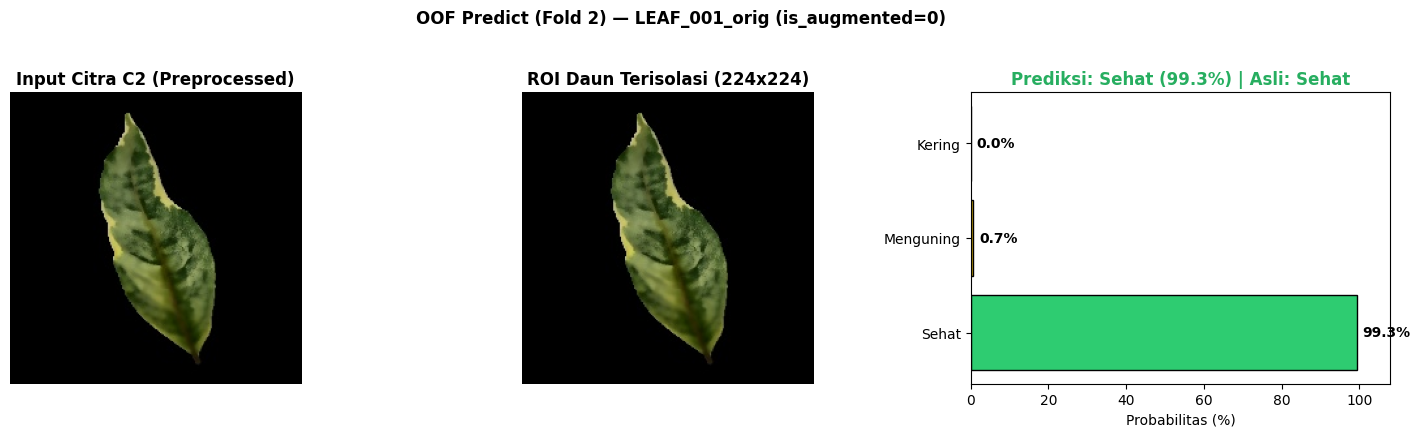

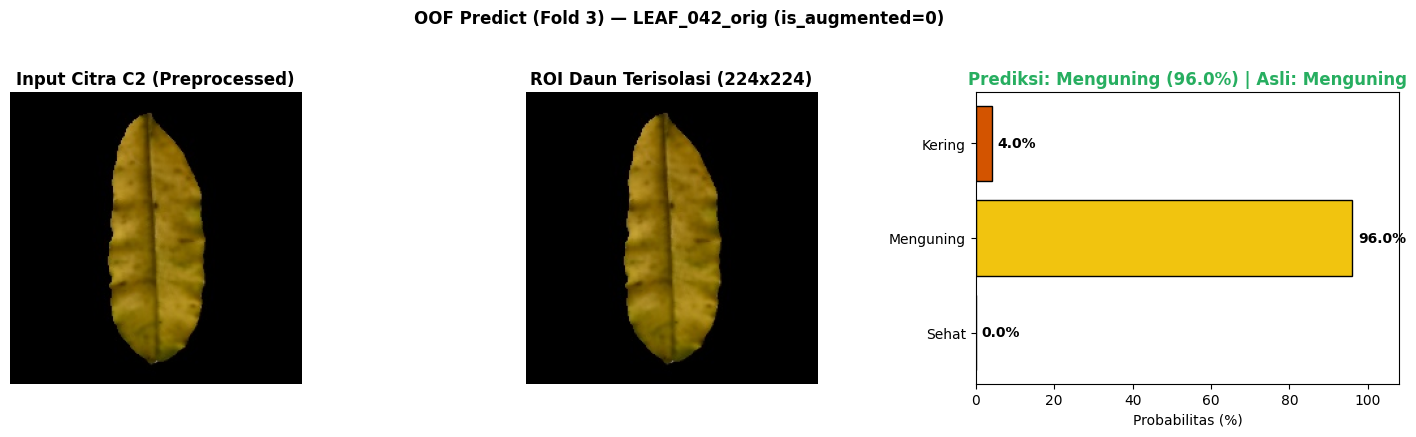

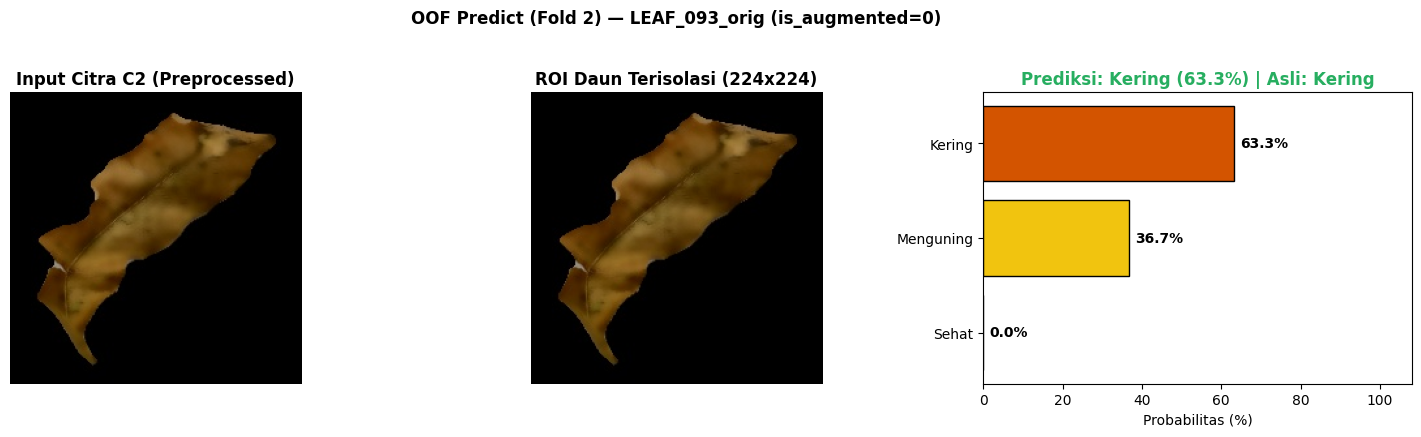

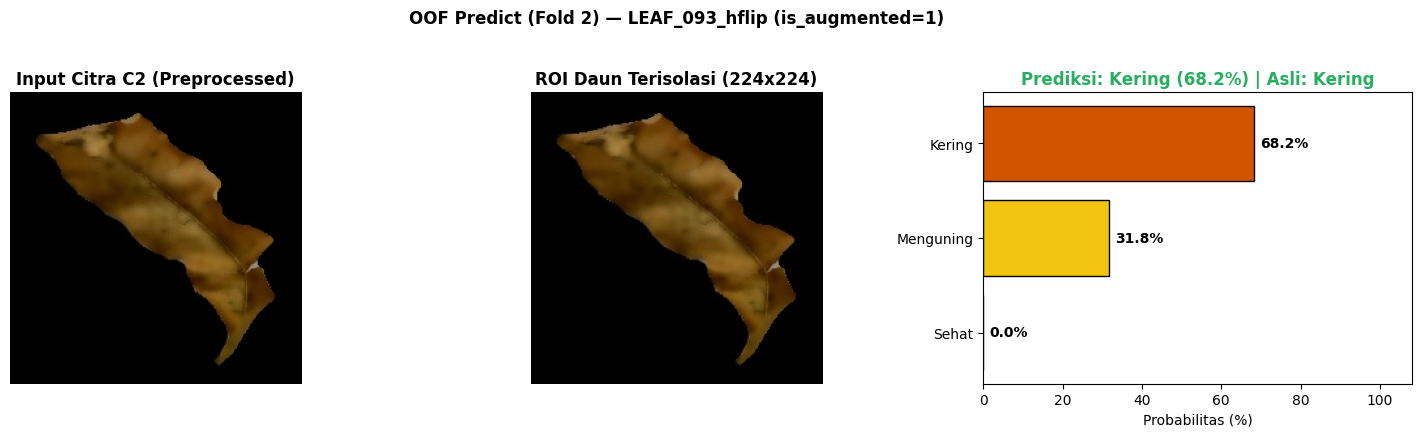

Verifikasi konsistensi fitur & simulasi OOF predict bebas leakage: SUKSES.


In [22]:
# ==============================================================================
# UJI 1: SIMULASI PREDICT BEBAS LEAKAGE MENGGUNAKAN OOF FOLD MODELS
# (Setiap gambar dari fold k diprediksi oleh model yang HANYA dilatih di fold != k)
# ==============================================================================
oof_bundle = joblib.load(os.path.join(OUT_BASE, 'models', 'oof_fold_models_A.pkl'))
feat_cols_loaded = oof_bundle['feature_cols']

# 1. Sanity check konsistensi: fitur hasil extract_handcrafted_features sama persis dengan CSV batch
sample_orig_rows = []
for cls_name in ['Sehat', 'Menguning', 'Kering']:
    row_cls = df_master_p2[(df_master_p2['label'] == cls_name) & (df_master_p2['is_augmented'] == 0)].iloc[0]
    sample_orig_rows.append(row_cls)

# Tambahkan juga 1 sampel hasil augmentasi untuk menunjukkan uji bebas leakage via model fold-nya
aug_row = df_master_p2[(df_master_p2['label'] == 'Kering') & (df_master_p2['is_augmented'] == 1)].iloc[0]
demo_rows = sample_orig_rows + [aug_row]

print(f"Menjalankan demo predict bebas leakage dengan {oof_bundle['model_name']} (OOF Fold Models)...")
for r in demo_rows:
    k_fold = int(r['fold'])
    fold_est = oof_bundle['fold_models'][k_fold]
    res = predict_leaf_image(
        image_path=r['path_C2_masked'],
        estimator=fold_est,
        feature_cols=feat_cols_loaded,
        true_label=r['label'],
        is_preprocessed_roi=True,
        mask_path=r['path_mask'],
        title_prefix=f"OOF Predict (Fold {k_fold}) — {r['sample_id']} (is_augmented={r['is_augmented']})"
    )

    # Cek konsistensi vektor fitur terhadap df_feat_A
    csv_row = df_feat_A[df_feat_A['sample_id'] == r['sample_id']].iloc[0]
    vec_live = np.array([res['features'][c] for c in feat_cols_loaded], dtype=np.float64)
    vec_csv  = csv_row[feat_cols_loaded].values.astype(np.float64)
    if not np.allclose(vec_live, vec_csv, rtol=1e-5, atol=1e-6, equal_nan=True):
        df_diff = pd.DataFrame({
            'fitur': feat_cols_loaded,
            'live': vec_live,
            'df_feat_A': vec_csv,
            'abs_diff': np.abs(vec_live - vec_csv)
        }).sort_values('abs_diff', ascending=False)
        print(f"\n[DIAGNOSTIK MISMATCH] {r['sample_id']} (Top 5 selisih terbesar):")
        print(df_diff.head(5).to_string(index=False))
        raise AssertionError(
            f"Fitur tidak sinkron pada {r['sample_id']} (max_diff={df_diff['abs_diff'].max():.6g}). "
            "Jalankan ulang Sel 4 (Bagian 1) atau Sel 12 dan Sel 15 agar df_feat_A & model sinkron dengan citra di Drive."
        )

print("Verifikasi konsistensi fitur & simulasi OOF predict bebas leakage: SUKSES.")

In [23]:
# ==============================================================================
# UJI 2: TEMPLATE PREDICT FOTO DAUN BARU EKSTERNAL (DI LUAR 127 DATA ASLI)
# ==============================================================================
final_bundle = joblib.load(os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl'))

# Isi path di bawah ini saat sudah memiliki foto daun baru dari HP / Sesi 3 (di luar 127 foto)
NEW_IMAGE_PATH = None  # Contoh: '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Uji_Baru/daun_tes_1.jpg'

if NEW_IMAGE_PATH is not None and os.path.exists(NEW_IMAGE_PATH):
    res_new = predict_leaf_image(
        image_path=NEW_IMAGE_PATH,
        estimator=final_bundle['pipeline'],
        feature_cols=final_bundle['feature_cols'],
        gamma_mode='auto',
        is_preprocessed_roi=False,
        title_prefix=f"Prediksi Foto Eksternal Baru ({final_bundle['model_name']})"
    )
    print(f"Hasil Prediksi : {res_new['pred_label']} (Confidence: {res_new['confidence']*100:.2f}%)")
    print(f"Probabilitas   : {res_new['probabilities']}")
else:
    print("Belum ada NEW_IMAGE_PATH yang diset / ditemukan.")
    print("Model final siap digunakan di:", os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl'))
    print("Saat sudah ada foto uji baru (misal Sesi 3 / demo live), isi variabel NEW_IMAGE_PATH lalu jalankan ulang sel ini.")

Belum ada NEW_IMAGE_PATH yang diset / ditemukan.
Model final siap digunakan di: /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/models/final_best_ml_model.pkl
Saat sudah ada foto uji baru (misal Sesi 3 / demo live), isi variabel NEW_IMAGE_PATH lalu jalankan ulang sel ini.
